In [1]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv("super_sms_dataset.csv", encoding="latin1")

df.head()

,SMSes,Labels
0,There be an update for your delivery CC 017281...,1.0
1,watch your favorite english movies of all genr...,1.0
2,aur what is the status for fms,0.0
3,hi shalini sundi thank you for dialling speci...,1.0
4,m tryin to understand too...,0.0


In [9]:
df['Labels'].value_counts()

Labels
0.0    40830
1.0    26178
Name: count, dtype: int64

In [10]:
df.columns

Index(['SMSes', 'Labels'], dtype='str')

In [11]:
df.isnull().sum()

SMSes     1
Labels    2
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.dropna(inplace = True)

In [14]:
df.shape

(67008, 2)

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 67008 entries, 0 to 67009
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SMSes   67008 non-null  str    
 1   Labels  67008 non-null  float64
dtypes: float64(1), str(1)
memory usage: 7.7 MB


In [17]:
df['SMSes'].head(10).tolist()

['There be an update for your delivery CC 01728161E due 09.06.2020 Tap here http://olo.me/3i6xF',
 'watch your favorite english movies of all genre like fast  furious  the thaw stepup  in just rs month to subscribe give a miss call on +91XXXXXXX ',
 'aur what is the status for fms',
 'hi shalini sundi thank you for dialling  special offer for you is talk to stars to subscribe  dial toll free now',
 'm tryin to understand too...',
 'vip number for sale   rs  cont kumar ',
 'Hee. Muacks. Love u dear!',
 'This be a reminder that your package will be deliver only when we receive the $57 pending amount',
 'Whoops let me convert it',
 'whats going on mate ?']

In [18]:
df['message_length'] = df['SMSes'].astype(str).apply(len)

df['message_length'].describe()

count    67008.000000
mean        96.095332
std         68.756874
min          2.000000
25%         42.000000
50%         89.000000
75%        136.000000
max       2695.000000
Name: message_length, dtype: float64

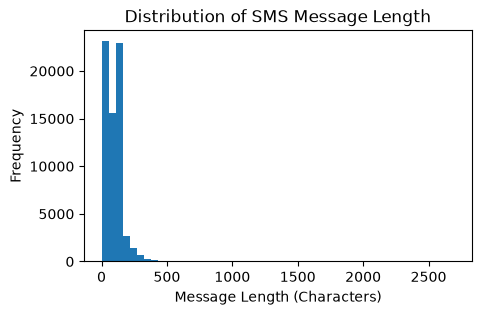

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(5,3))
plt.hist(df['message_length'], bins=50)
plt.title('Distribution of SMS Message Length')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Frequency')
plt.show()

In [22]:
df.groupby('Labels')['message_length'].describe()

,count,mean,std,min,25%,50%,75%,max
Labels,,,,,,,,
0.0,40830.0,65.190228,56.576753,2.0,30.0,50.0,81.0,1474.0
1.0,26178.0,144.298228,57.405188,19.0,121.0,136.0,150.0,2695.0


Observation 1: Label 1 messages are considerably longer.
- Label 0 average: 65 characters.
- Label 1 average: 144 characters.
Label 1 messages are, on average, more than twice as long.

Observation 2: The median also differs significantly.
- Label 0: 50 characters.
- Label 1: 136 characters.

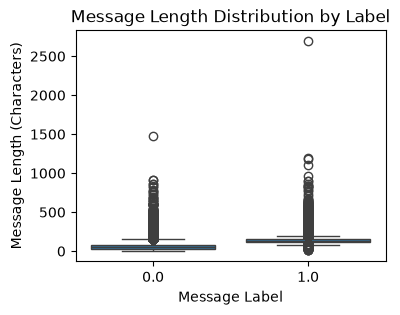

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 3))
sns.boxplot(
    data=df,
    x='Labels',
    y='message_length'
)
plt.title('Message Length Distribution by Label')
plt.xlabel('Message Label')
plt.ylabel('Message Length (Characters)')
plt.show()

In [25]:
df.groupby('Labels')['SMSes'].sample(5, random_state=42).tolist()

['I need to go simlim get some stuff. See got what then decide but likely to be after lunch',
 'Oh okie lor... Cos if got nothin much den i wont go lor...',
 'I want to speak with you urgently.Please call me.',
 'Hey lao po, thks for helping me todae! lemme noe if u want to hav dinner 2gether..think i wanna go shopping at plaza sing ltr.Saw some nice clothes juz now.Haha',
 "Hahaha dont worry it's alright :-D",
 'dear all  hottest offer   avail  months   days gym membership in just  offer valid till limited time team measure ',
 'get a gift voucher of rs on purchase of rs offer valid on sarees and salwars tc apply mm bhimavaram',
 'special offer on callertune only for you just dial  tollfree to get callertune only at rs',
 'Lloyds ALERT An unknown device have request an unregistered payee on 09/12 If this be NOT you please visit Securepaylogin.com/',
 'for your travel starting  feb  for bangalore delhi makemytrip booking id nf amount charged rs  download app http bit ly ursyr use booki

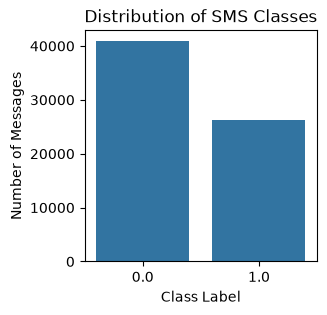

In [28]:
plt.figure(figsize=(3,3))
sns.countplot(data=df, x='Labels')
plt.title('Distribution of SMS Classes')
plt.xlabel('Class Label')
plt.ylabel('Number of Messages')
plt.show()

In [30]:
from collections import Counter
import re

# Function to clean text and extract words
def get_words(text):
    text = re.sub(r"[^a-zA-Z\s]", "", str(text))
    words = text.lower().split()
    return words

# Extract words from label 0
all_words_0 = df[df['Labels'] == 0]['SMSes'].dropna().apply(get_words).sum()

# Extract words from label 1
all_words_1 = df[df['Labels'] == 1]['SMSes'].dropna().apply(get_words).sum()

# Count word frequencies
word_counts_0 = Counter(all_words_0)
word_counts_1 = Counter(all_words_1)

# Get top 20 words
print("Top words in Label 0:")
print(word_counts_0.most_common(20))

print("\nTop words in Label 1:")
print(word_counts_1.most_common(20))

Top words in Label 0:
[('i', 17902), ('to', 11313), ('u', 9409), ('the', 9296), ('you', 9002), ('haha', 5648), ('a', 5446), ('me', 4721), ('my', 4677), ('in', 4657), ('is', 4609), ('for', 4496), ('and', 4463), ('it', 3973), ('so', 3937), ('can', 3793), ('at', 3757), ('of', 3140), ('go', 3066), ('not', 3054)]

Top words in Label 1:
[('to', 16282), ('your', 15891), ('on', 11493), ('for', 11305), ('rs', 8190), ('you', 8118), ('get', 7993), ('the', 7725), ('be', 7405), ('a', 5683), ('of', 5584), ('and', 5491), ('in', 5470), ('at', 5087), ('with', 4964), ('call', 4733), ('free', 4665), ('now', 4624), ('offer', 4200), ('off', 4054)]


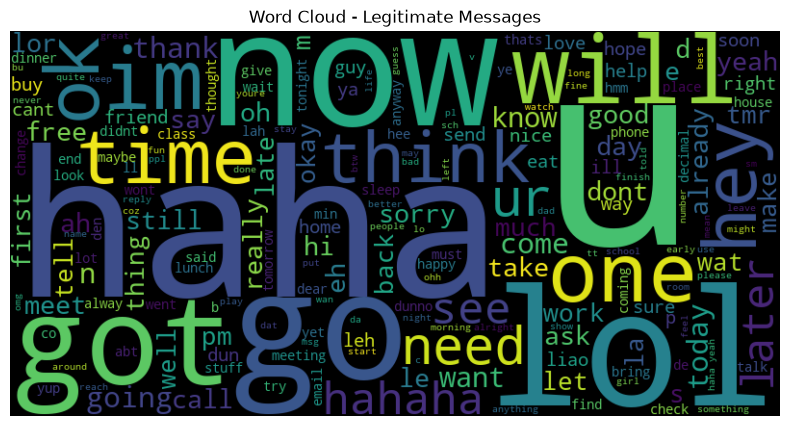

In [31]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud_0 = WordCloud(
    width=800,
    height=400,
    background_color="black"
).generate(" ".join(all_words_0))

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_0, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Legitimate Messages")
plt.show()


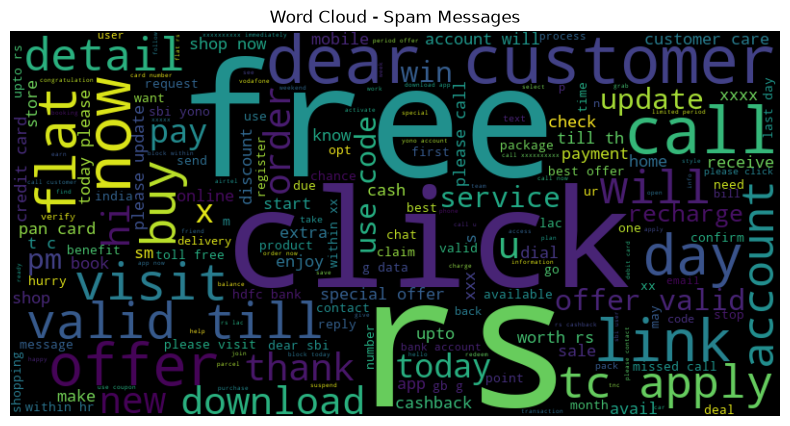

In [32]:
wordcloud_1 = WordCloud(
    width=800,
    height=400,
    background_color="black"
).generate(" ".join(all_words_1))

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_1, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Spam Messages")
plt.show()

In [33]:
import re
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

def clean(doc):
    # Convert to lower case
    doc = doc.lower()
    # Replace URLs
    doc = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', doc)
    # Replace digits
    doc = re.sub(r'\d+', ' numbertoken ', doc)
    # Remove special character
    regex = "[^a-zA-Z.]"
    doc = re.sub(regex, " ", doc)
    # Tokenization
    tokens = nltk.word_tokenize(doc)
    # Stopwords removal
    stop_words = set(stopwords.words('english'))
    filtered_tokens = [word for word in tokens if word not in stop_words]
    # Lemmatization
    lemmatizer = WordNetLemmatizer()
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]

    # Join and return
    return " ".join(lemmatized_tokens)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [34]:
df = df.dropna(subset=['SMSes', 'Labels'])

In [35]:
df['cleaned_SMS'] = df['SMSes'].apply(clean)

In [36]:
df.to_csv("cleansms.csv", index=False)